# Week 2 - Task 4: Data Visualization (Matplotlib)
The cleaned dataset (`students_clean.csv`, produced in Task 3) is visualised with four chart types.

In [1]:
import pandas as pd
pd.set_option('display.width', 120); pd.set_option('display.max_columns', 20)
import matplotlib.pyplot as plt
df = pd.read_csv("students_clean.csv")
df["Average"] = df[["Math", "Science", "English"]].mean(axis=1)
df.head()

   Student_ID            Name  Gender  Age  Study_Hours  Attendance  Math  Science  English    Average
0        1052    Deepa Sharma  Female   19          2.9        66.0  36.0     50.0     54.0  46.666667
1        1003      Swathi Rao  Female   18          3.1        89.0  43.0     37.0     43.0  41.000000
2        1079  Prakash Sharma    Male   20          5.4        80.0  45.0     47.0     51.0  47.666667
3        1010      Divya Nair    Male   19          1.4        76.0  22.0     29.0     50.0  33.666667
4        1017  Keerthi Pillai    Male   17          6.2        74.0  60.0     62.0     47.0  56.333333

## 1. Bar chart - average marks in each subject

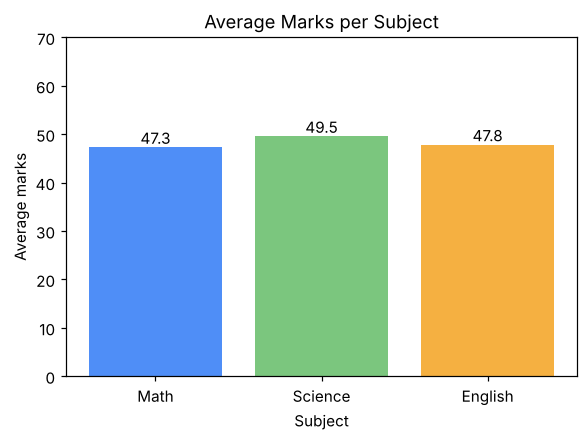

In [2]:
avg = df[["Math", "Science", "English"]].mean()
plt.figure(figsize=(6, 4))
bars = plt.bar(avg.index, avg.values, color=["#4f8ef7", "#7bc67e", "#f5b041"])
plt.bar_label(bars, fmt="%.1f")
plt.title("Average Marks per Subject"); plt.xlabel("Subject"); plt.ylabel("Average marks")
plt.ylim(0, 70)
plt.show()

**Explanation:** The bar chart compares the class average of the three subjects. All three are close to 48 marks, with Science slightly the highest.

## 2. Line chart - average marks vs daily study hours

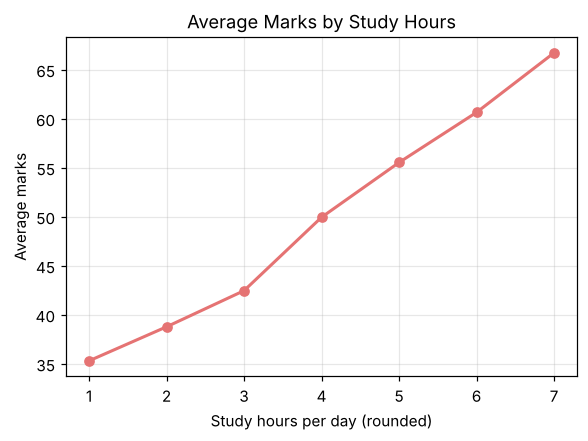

In [3]:
df["Hours_Group"] = df["Study_Hours"].round().astype(int)
trend = df.groupby("Hours_Group")["Average"].mean()
plt.figure(figsize=(6, 4))
plt.plot(trend.index, trend.values, marker="o", color="#e57373", linewidth=2)
plt.title("Average Marks by Study Hours"); plt.xlabel("Study hours per day (rounded)"); plt.ylabel("Average marks")
plt.grid(alpha=0.3)
plt.show()

**Explanation:** The line rises steadily, showing that students who study more hours per day tend to score higher average marks.

## 3. Histogram - distribution of average marks

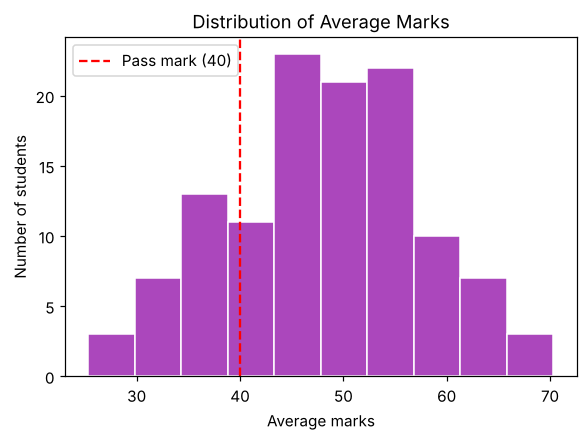

In [4]:
plt.figure(figsize=(6, 4))
plt.hist(df["Average"], bins=10, color="#ab47bc", edgecolor="white")
plt.axvline(40, color="red", linestyle="--", label="Pass mark (40)")
plt.title("Distribution of Average Marks"); plt.xlabel("Average marks"); plt.ylabel("Number of students")
plt.legend()
plt.show()

**Explanation:** Most students have average marks between about 35 and 60. The red dashed line marks the pass mark of 40; the students to its left have failed.

## 4. Scatter plot - study hours vs average marks

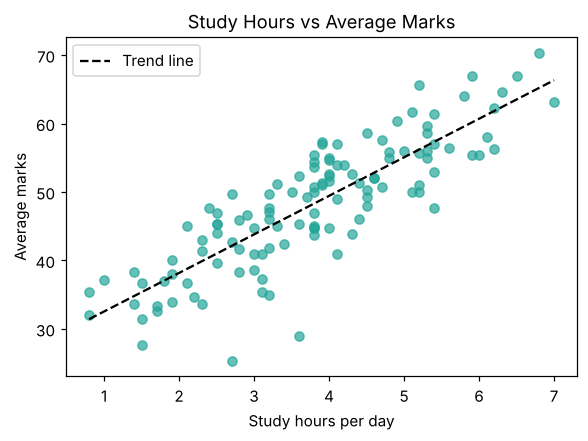

In [5]:
import numpy as np
plt.figure(figsize=(6, 4))
plt.scatter(df["Study_Hours"], df["Average"], color="#26a69a", alpha=0.7)
m, c = np.polyfit(df["Study_Hours"], df["Average"], 1)       # best-fit straight line
x = np.linspace(df["Study_Hours"].min(), df["Study_Hours"].max(), 50)
plt.plot(x, m * x + c, color="black", linestyle="--", label="Trend line")
plt.title("Study Hours vs Average Marks"); plt.xlabel("Study hours per day"); plt.ylabel("Average marks")
plt.legend()
plt.show()

**Explanation:** The points move upward from left to right, which shows a strong positive relationship: more study hours go with higher marks.